# Validação de Física, Pneus, Combustível e Clima — ApexSim
**Membro:** Isaac do Nascimento Oliveira — *Física & Eventos (`sim/physics.py`, `sim/weather.py`)*  
**Marcos:** M0 (Fundamentação Teórica), M1 (Verticais Isoladas D5), M4 (Modelo Climático e Crossover)  
**Fundamentação Completa:** `docs/fisica.md` (Seções 1, 2 e 6)

Este notebook separa explicitamente o que vem de **dados empíricos / literatura** do que é **hipótese de modelagem**:
1. **Pneus Slicks (Soft, Medium, Hard)**:
   - *Dado empírico (Entrega D5 — Octávio)*: 39.966 voltas limpas em 44 GPs (FastF1/Kaggle 2023–2024), com medição até `idade_max_suportada` (19v no Soft, 29v no Medium, 41v no Hard), de onde saem $k_{1,quad}$ e $k_{2,lin}$.
   - *Hipótese de modelagem (sem dado empírico)*: Como as equipes param antes do colapso térmico (`cliff: null` no JSON), os parâmetros de *cliff* ($a_{cliff} \in \{25, 35, 47\}$ voltas, $\Delta_{cliff}$, $\beta$) e a escala $\tau = 3,0\text{ s}$ de conversão em grip são escolhas de modelagem posicionadas além da faixa observada para preservar o IC 95% medido.
2. **Penalidade por Massa de Combustível**:
   - *Parâmetro fixado da literatura*: $s_{mass} = 0,03\text{ s/kg}$ ($0,30\text{ s por 10 kg}$, McLaren Applied [6]), dentro da faixa de $0,03\text{–}0,08\text{ s/kg}$ da literatura e do critério do roadmap ($0,2\text{–}0,5\text{ s por 10 kg}$).
3. **Modelo Climático e Crossover de Compostos (M4)**:
   - *Literatura*: Penalidade base de ritmo do Full Wet em chuva forte de $+3,0\text{ s/volta}$ (degradação $\approx 0,035\text{ s/volta}$) e degradação do Intermediário $\approx 0,060\text{ s/volta}$ [29].
   - *Hipótese de modelagem*: Matriz de transição de Markov (3 estados: `seco`, `umido`, `molhado`) e matriz de penalidades fora da condição ideal de cada pneu, parametrizadas para reproduzir o ordenamento qualitativo de crossover (`Slick < Inter < Wet` no seco, `Inter < Wet < Slick` no úmido e `Wet < Inter < Slick` no molhado).


In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

backend_dir = Path("../../backend").resolve()
if str(backend_dir) not in sys.path:
    sys.path.insert(0, str(backend_dir))

from sim.physics import (
    tyre_grip,
    tyre_time_loss,
    fuel_time_delta,
    TYRE_TABLE,
)
from sim.weather import (
    weather_time_delta,
    weather_grip_factor,
)

data_path = Path("../../data/curvas_degradacao/curvas_degradacao.json")
with open(data_path, encoding="utf-8") as f:
    kaggle_data = json.load(f)

print(f"Fonte dos dados reais: {kaggle_data['meta']['fonte']}")
print(f"Total de voltas limpas analisadas: {kaggle_data['meta']['n_voltas_limpas']}")
print(f"Compostos em TYRE_TABLE: {list(TYRE_TABLE.keys())}")


Fonte dos dados reais: vanshbatra26/f1-tyre-strategy-engine-datasets (FastF1), corridas 2023-2024
Total de voltas limpas analisadas: 39966
Compostos em TYRE_TABLE: ['soft', 'medium', 'hard', 'intermediate', 'wet']


## 1. Curva de Degradação e Projeção de Grip: Modelo vs. Dados Empíricos (D5)

- **Linha superior (Perda de Tempo)**: Compara a perda medida no dataset D5 (`perda_s` $\pm 1,96 \cdot \text{erro\_padrao\_s}$, IC 95%) com a curva de `tyre_time_loss(c, a) - tyre_time_loss(c, 2)`.
- **Linha inferior (Fator de Grip)**: A telemetria mede tempo de volta, não coeficiente de atrito. O fator `tyre_grip` é uma projeção monotônica definida por $g(a, c) = \frac{1}{1 + \Delta t / \tau}$ com $\tau = 3,0\text{ s}$ (*hipótese de escala*). Os pontos pretos na linha inferior mostram a mesma transformação aplicada aos pontos de `perda_s` do D5.

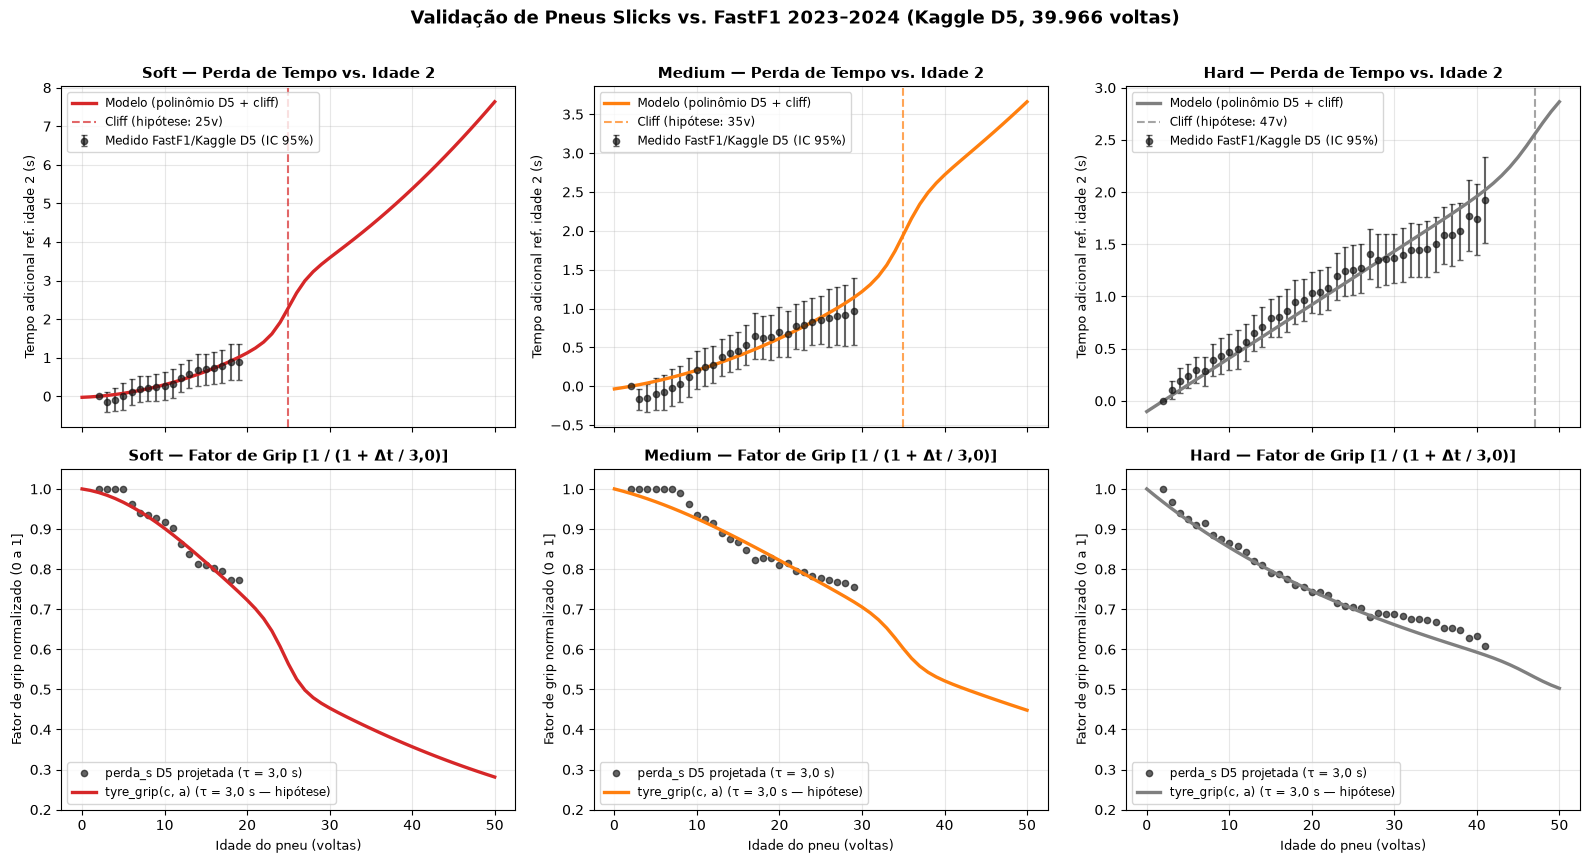

In [2]:
compounds = ["soft", "medium", "hard"]
comp_keys = {"soft": "SOFT", "medium": "MEDIUM", "hard": "HARD"}
colors = {"soft": "#d62728", "medium": "#ff7f0e", "hard": "#7f7f7f"}

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharex=True)
ages_model = np.arange(0, 51)

for idx, c in enumerate(compounds):
    c_key = comp_keys[c]
    curva_real = kaggle_data["compostos"][c_key]["curva"]
    idades_reais = [pt["idade"] for pt in curva_real]
    perdas_reais = [pt["perda_s"] for pt in curva_real]
    erros_reais = [pt["erro_padrao_s"] for pt in curva_real]
    grip_proj_real = [1.0 / (1.0 + max(0.0, pt["perda_s"]) / 3.0) for pt in curva_real]

    perdas_modelo = [tyre_time_loss(c, a) - tyre_time_loss(c, 2) for a in ages_model]
    grip_modelo = [tyre_grip(c, a) for a in ages_model]

    ax_loss = axes[0, idx]
    ax_loss.errorbar(
        idades_reais,
        perdas_reais,
        yerr=[1.96 * e for e in erros_reais],
        fmt="o",
        color="#111111",
        alpha=0.65,
        markersize=4.5,
        capsize=2.5,
        label="Medido FastF1/Kaggle D5 (IC 95%)",
    )
    ax_loss.plot(
        ages_model,
        perdas_modelo,
        "-",
        color=colors[c],
        lw=2.4,
        label="Modelo (polinômio D5 + cliff)",
    )
    ax_loss.axvline(
        TYRE_TABLE[c].cliff_age,
        color=colors[c],
        ls="--",
        alpha=0.7,
        lw=1.5,
        label=f"Cliff (hipótese: {TYRE_TABLE[c].cliff_age:.0f}v)",
    )
    ax_loss.set_title(f"{c.capitalize()} — Perda de Tempo vs. Idade 2", fontsize=11, fontweight="bold")
    ax_loss.set_ylabel("Tempo adicional ref. idade 2 (s)", fontsize=9.5)
    ax_loss.grid(alpha=0.3)
    ax_loss.legend(fontsize=8.5, loc="upper left")

    ax_grip = axes[1, idx]
    ax_grip.plot(
        idades_reais,
        grip_proj_real,
        "o",
        color="#111111",
        alpha=0.65,
        markersize=4.5,
        label="perda_s D5 projetada (τ = 3,0 s)",
    )
    ax_grip.plot(
        ages_model,
        grip_modelo,
        "-",
        color=colors[c],
        lw=2.4,
        label="tyre_grip(c, a) (τ = 3,0 s — hipótese)",
    )
    ax_grip.set_title(f"{c.capitalize()} — Fator de Grip [1 / (1 + Δt / 3,0)]", fontsize=11, fontweight="bold")
    ax_grip.set_xlabel("Idade do pneu (voltas)", fontsize=9.5)
    ax_grip.set_ylabel("Fator de grip normalizado (0 a 1]", fontsize=9.5)
    ax_grip.grid(alpha=0.3)
    ax_grip.set_ylim(0.2, 1.05)
    ax_grip.legend(fontsize=8.5, loc="lower left")

plt.suptitle(
    "Validação de Pneus Slicks vs. FastF1 2023–2024 (Kaggle D5, 39.966 voltas)",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.savefig("validacao_pneus_grip.png", dpi=130, bbox_inches="tight")
plt.show()


## 2. Verificação de Vida Útil e Ordenação Pós-Cliff

Nota metodológica importante para apresentação:
- Na medição agregada do D5, a curva do **Hard** apresenta inclinação linear superior à do **Medium** ($0,051\text{ s/v}$ vs. $0,016\text{ s/v}$). A hipótese de que isso decorre de viés de seleção de circuitos (o Hard sendo mais usado em pistas abrasivas) não é testável no agregado.
- Por isso, a hierarquia clássica de durabilidade ($\text{Soft} < \text{Medium} < \text{Hard}$) foi modelada via idade de *cliff* ($25 < 35 < 47$ voltas) e magnitude do salto ($\Delta_{cliff} = 1,2 > 0,8 > 0,5\text{ s}$).

In [3]:
age_check = 38
losses = {c: tyre_time_loss(c, age_check) for c in compounds}
print(f"Perda de tempo na volta {age_check} (após o cliff hipotético do Medium em 35v):")
for c, v in losses.items():
    print(f"  {c.capitalize():>6}: {v:.3f} s (cliff_age = {TYRE_TABLE[c].cliff_age:.0f} voltas)")

assert TYRE_TABLE["soft"].cliff_age < TYRE_TABLE["medium"].cliff_age < TYRE_TABLE["hard"].cliff_age
assert losses["soft"] > losses["medium"] > losses["hard"]
print("\nOK: cliff_age (Soft < Medium < Hard) e perda pós-cliff na volta 38 (Soft > Medium > Hard).")


Perda de tempo na volta 38 (após o cliff hipotético do Medium em 35v):
    Soft: 5.011 s (cliff_age = 25 voltas)
  Medium: 2.527 s (cliff_age = 35 voltas)
    Hard: 1.950 s (cliff_age = 47 voltas)

OK: cliff_age (Soft < Medium < Hard) e perda pós-cliff na volta 38 (Soft > Medium > Hard).


## 3. Penalidade por Massa de Combustível (Parâmetro Fixado da Literatura)

O modelo utiliza a relação linear $\Delta t_{fuel}(m) = s_{mass} \cdot m$ com coeficiente fixado em $s_{mass} = 0,03\text{ s/kg}$ ($0,30\text{ s por 10 kg}$), valor reportado pela McLaren Applied (citado em [6], `docs/fisica.md` Seção 2.3). O gráfico abaixo situa essa escolha dentro da faixa de aceite do roadmap ($0,20\text{–}0,50\text{ s / 10 kg}$).

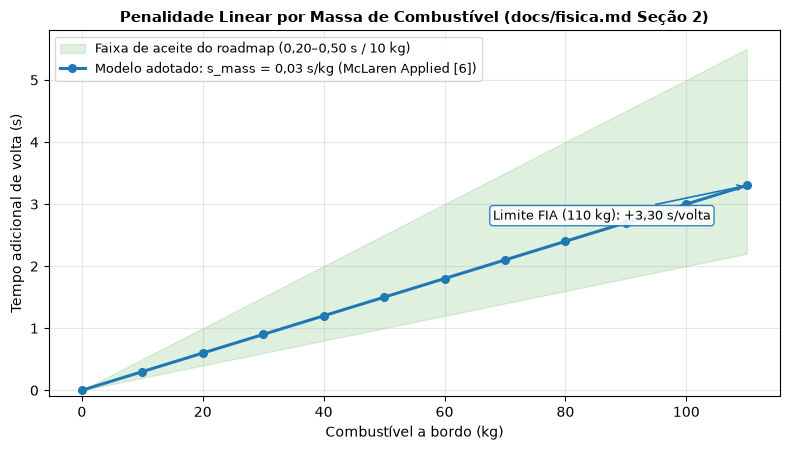

Delta por 10 kg: 0.300 s (critério M1: 0,20 a 0,50 s)


In [4]:
fuel_levels = np.arange(0, 111, 10)
deltas = [fuel_time_delta(m) for m in fuel_levels]

fig, ax = plt.subplots(figsize=(8, 4.6))

ax.fill_between(
    fuel_levels,
    0.02 * fuel_levels,
    0.05 * fuel_levels,
    color="tab:green",
    alpha=0.15,
    label="Faixa de aceite do roadmap (0,20–0,50 s / 10 kg)",
)

ax.plot(
    fuel_levels,
    deltas,
    marker="o",
    markersize=5.5,
    color="tab:blue",
    lw=2.2,
    label="Modelo adotado: s_mass = 0,03 s/kg (McLaren Applied [6])",
)

ax.annotate(
    "Limite FIA (110 kg): +3,30 s/volta",
    xy=(110, fuel_time_delta(110)),
    xytext=(68, 2.75),
    arrowprops=dict(arrowstyle="->", color="tab:blue", lw=1.2),
    fontsize=9,
    bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="tab:blue", alpha=0.9),
)

ax.set_title("Penalidade Linear por Massa de Combustível (docs/fisica.md Seção 2)", fontsize=11, fontweight="bold")
ax.set_xlabel("Combustível a bordo (kg)", fontsize=10)
ax.set_ylabel("Tempo adicional de volta (s)", fontsize=10)
ax.grid(alpha=0.3)
ax.set_ylim(-0.1, 5.8)
ax.legend(loc="upper left", fontsize=9, frameon=True)

plt.tight_layout()
plt.savefig("validacao_combustivel.png", dpi=130, bbox_inches="tight")
plt.show()

delta_10kg = fuel_time_delta(10) - fuel_time_delta(0)
print(f"Delta por 10 kg: {delta_10kg:.3f} s (critério M1: 0,20 a 0,50 s)")
assert 0.2 <= delta_10kg <= 0.5


## 4. Modelo Climático e Crossover de Compostos — Marco M4 (`sim/weather.py`)

Distinção entre literatura e hipótese de modelagem para apresentação:
- **Literatura (`docs/fisica.md` Seção 6.4 [29])**: Penalidade base de ritmo do pneu `wet` em pista molhada de $+3,0\text{ s/volta}$ (taxa linear de degradação $\approx 0,035\text{ s/volta}$) e degradação do `intermediate` $\approx 0,060\text{ s/volta}$.
- **Hipóteses de modelagem (`sim/weather.py`)**: Como a FIA não publica matriz de Markov nem tabela de penalidades cruzadas (ex.: slick em pista molhada), as probabilidades de transição entre `seco`, `umido` e `molhado` e as penalidades fora da condição ideal foram definidas heuristicamente para garantir as janelas de *crossover*:
  - `seco` ($\theta = 0,0$): Slicks ($+0,0\text{ s}$) superam Intermediário ($+3,6\text{ s}$) e Wet ($+7,8\text{ s}$).
  - `umido` ($\theta = 0,40$): Intermediário ($+1,2\text{ s}$) supera Wet ($+4,5\text{ s}$) e Slicks ($+5,5\text{ a }+7,0\text{ s}$).
  - `molhado` ($\theta = 0,85$): Wet ($+3,0\text{ s}$, ref. [29]) supera Intermediário ($+6,8\text{ s}$) e Slicks ($+18,0\text{ a }+22,0\text{ s}$).

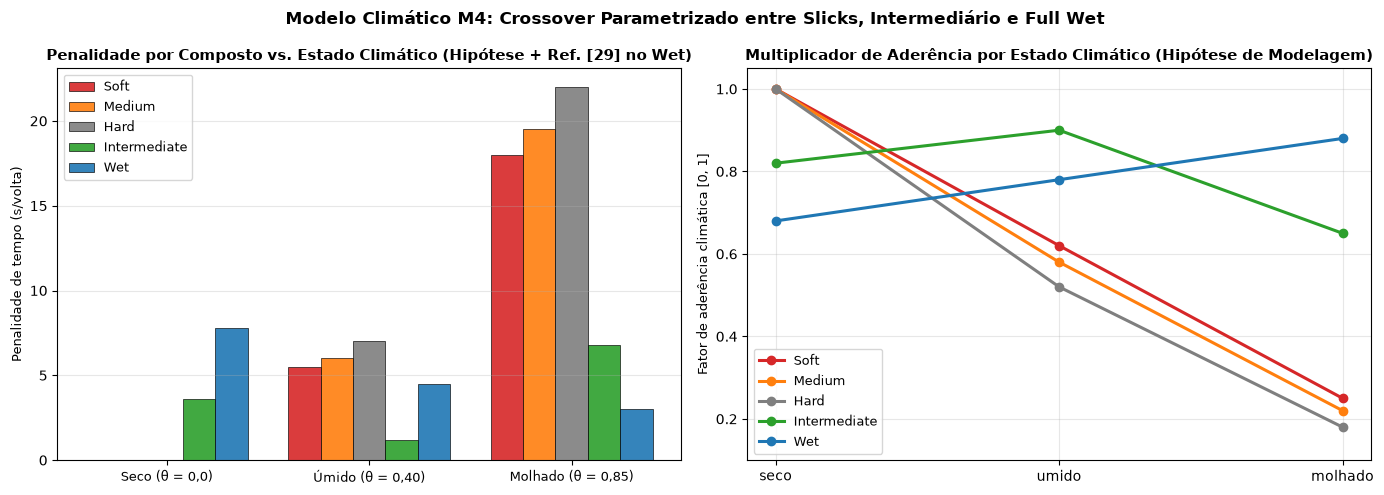

In [5]:
weather_states = ["seco", "umido", "molhado"]
comp_palette = {
    "soft": "#d62728",
    "medium": "#ff7f0e",
    "hard": "#7f7f7f",
    "intermediate": "#2ca02c",
    "wet": "#1f77b4",
}

fig, (ax_cross, ax_wgrip) = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(weather_states))
width = 0.16

for i, (comp, col) in enumerate(comp_palette.items()):
    deltas_clima = [weather_time_delta(comp, ws) for ws in weather_states]
    grips_clima = [weather_grip_factor(comp, ws) for ws in weather_states]

    ax_cross.bar(
        x + (i - 2) * width,
        deltas_clima,
        width,
        label=comp.capitalize(),
        color=col,
        alpha=0.9,
        edgecolor="black",
        linewidth=0.5,
    )
    ax_wgrip.plot(
        weather_states,
        grips_clima,
        marker="o",
        lw=2.2,
        label=comp.capitalize(),
        color=col,
    )

ax_cross.set_xticks(x)
ax_cross.set_xticklabels(["Seco (θ = 0,0)", "Úmido (θ = 0,40)", "Molhado (θ = 0,85)"], fontsize=9.5)
ax_cross.set_ylabel("Penalidade de tempo (s/volta)", fontsize=9.5)
ax_cross.set_title("Penalidade por Composto vs. Estado Climático (Hipótese + Ref. [29] no Wet)", fontsize=10.5, fontweight="bold")
ax_cross.grid(axis="y", alpha=0.3)
ax_cross.legend(fontsize=9)

ax_wgrip.set_ylabel("Fator de aderência climática [0, 1]", fontsize=9.5)
ax_wgrip.set_title("Multiplicador de Aderência por Estado Climático (Hipótese de Modelagem)", fontsize=10.5, fontweight="bold")
ax_wgrip.grid(alpha=0.3)
ax_wgrip.set_ylim(0.1, 1.05)
ax_wgrip.legend(fontsize=9)

plt.suptitle("Modelo Climático M4: Crossover Parametrizado entre Slicks, Intermediário e Full Wet", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("validacao_clima_crossover.png", dpi=130, bbox_inches="tight")
plt.show()


## 5. Resumo de Rastreabilidade: Dados vs. Hipóteses (M0, M1 e M4)

| Subsistema | O que vem de Dados / Literatura | O que é Hipótese de Modelagem |
|---|---|---|
| **Pneus Slicks (M1)** | Coeficientes $k_{1,quad}$ e $k_{2,lin}$ ajustados em 39.966 voltas (FastF1/Kaggle D5). | Idades de *cliff* (`25`, `35`, `47`v), $\Delta_{cliff}$, $\beta$ e escala $\tau = 3,0\text{ s}$ de `tyre_grip`. |
| **Pneus de Chuva (M4)** | Degradação linear $k_{2,lin}$ (`0,060` no Inter, `0,035` no Wet) e $+3,0\text{ s}$ do Wet em chuva [29]. | Parâmetros de *cliff* e penalidades cruzadas fora da condição ideal (ex.: slick no molhado). |
| **Combustível (M1)** | Sensibilidade $s_{mass} = 0,03\text{ s/kg}$ (McLaren Applied [6]) e limite de $110\text{ kg}$ (FIA [8]). | Queima linear por volta sem variação por modo de motor. |
| **Cadeia Climática (M4)** | Propriedade de Markov (SFU [31]) e regras operacionais de pneus de chuva (FIA [30]). | Probabilidades da matriz de transição `DEFAULT_TRANSITION_PROBABILITIES` e $\theta$ discreto. |
